In [ ]:
import numpy as np

prepared = np.load("prepared_data.npz")

X_train = prepared["X_train"]
Y_train = prepared["Y_train"]

X_dev = prepared["X_dev"]
Y_dev = prepared["Y_dev"]

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

print("NumPy:", np.__version__)
print("Matplotlib is ready!")

NumPy: 2.4.6
Matplotlib is ready!


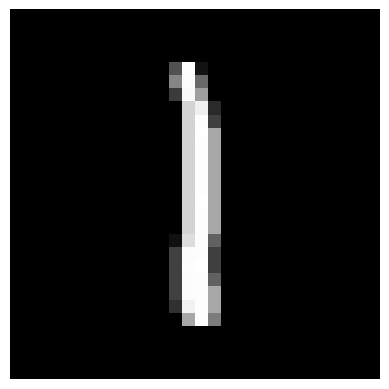

In [ ]:
image = X_train[:, 0]

image = image.reshape(28, 28)  #transforms its 784 pixel values into a 28 × 28 matrix.

plt.imshow(image, cmap='gray')  #displays that matrix as an image and displays it in grayscale.
plt.axis('off') #hides the coordinate axes
plt.show()

In [ ]:
print( " correct digit is ", Y_train[0])

 correct digit is  1


In [ ]:
def init_paramet():
    W1 = np.random.rand(10, 784) - 0.5
    b1 = np.random.rand(10, 1) - 0.5
    W2 = np.random.rand(10, 10) - 0.5
    b2 = np.random.rand(10, 1) - 0.5
    return W1, W2, b1, b2

In [ ]:
# declarer les 2 fcts d activations qu ona a
def reLU(Z) :
  return np.maximum(0 , Z)

def softmax (Z):
    A = np.exp(Z)/ sum(np.exp(Z))
    return A



In [ ]:
#time for forward propagation !
def forward_prop(W1 , b1 , W2 , b2 , X):
  Z1 = W1.dot(X) + b1
  A1 = reLU(Z1)

  Z2 = W2.dot(A1) + b2
  A2 = softmax(Z2)
  return Z1 , A1 , Z2 , A2

In [ ]:
# now lets call it using our train data
W1, W2, b1, b2 = init_paramet()
Z1, A1, Z2, A2 = forward_prop(W1, b1, W2, b2, X_train)
print("Z1:", Z1.shape)
print("A1:", A1.shape)
print("Z2:", Z2.shape)
print("A2:", A2.shape)
print(np.sum(A2[:, 0]))

Z1: (10, 41000)
A1: (10, 41000)
Z2: (10, 41000)
A2: (10, 41000)
1.0


In [ ]:
#defintion of the one hot function
def one_hot(Y):
    one_hot_Y = np.zeros((Y.size, 10))
    one_hot_Y[np.arange(Y.size), Y] = 1
    return one_hot_Y.T


Y_one_hot = one_hot(Y_train)
print(Y_train[0])
print(Y_one_hot[:, 0])
print(Y_one_hot.shape)

1
[0. 1. 0. 0. 0. 0. 0. 0. 0. 0.]
(10, 41000)


In [ ]:
def derivee_ReLU(Z):
    return Z > 0

In [ ]:
def backward_propa (Z1 , A1 , Z2 , A2 , W1 , W2 , X , Y) :
  one_hot_Y = one_hot(Y)
  dZ2 = A2 - one_hot_Y
  m = Y_train.size
  dW2 = 1/m * dZ2.dot(A1.T)
  db2 = 1 / m * np.sum(dZ2, axis=1, keepdims=True)
  dZ1 = W2.T.dot(dZ2) * derivee_ReLU(Z1)
  dW1 = 1 / m * dZ1.dot(X.T)
  db1 = 1/ m * np.sum(dZ1 , axis = 1 , keepdims = True)
  return dW1 , db1 , dW2 , db2

In [ ]:
# c' est l etape de la mise a jour
def upgrade_param(W1 , W2 , b1 , b2 ,dW1 , db1 , dW2 , db2 , alpha ): # alpha c est le learning rate
        W1 = W1 - alpha * dW1
        b1 = b1 - alpha * db1
        W2 = W2 - alpha * dW2
        b2 = b2 - alpha * db2
        return W1 , b1 , W2 , b2

In [ ]:
def get_predictions(A2):
    return np.argmax(A2, axis=0)

def get_accuracy(predictions, Y):
    return np.sum(predictions == Y) / Y.size

In [ ]:
def gradient_descent(X, Y, alpha, iterations):
    W1, W2, b1, b2 = init_paramet()
    m = Y.size
    for i in range(iterations):
        Z1, A1, Z2, A2 = forward_prop(W1, b1, W2, b2, X)
        dW1, db1, dW2, db2 = backward_propa(Z1, A1, Z2, A2, W1, W2, X, Y)
        W1, b1, W2, b2 = upgrade_param(W1, W2, b1, b2, dW1, db1, dW2, db2, alpha)

        if i % 10 == 0:
            print("Iteration: ", i)
            predictions = get_predictions(A2)
            accuracy = get_accuracy(predictions, Y)
            print("ACCURACY : ", accuracy)

    return W1, b1, W2, b2

In [ ]:
import numpy as np

prepared = np.load("prepared_data.npz")

X_train = prepared["X_train"]
Y_train = prepared["Y_train"]

X_dev = prepared["X_dev"]
Y_dev = prepared["Y_dev"]

In [ ]:
W1, b1, W2, b2 = gradient_descent( X_train , Y_train , 0.1 , 601 )

Iteration:  0
ACCURACY :  0.17441463414634145
Iteration:  10
ACCURACY :  0.30253658536585365
Iteration:  20
ACCURACY :  0.3918536585365854
Iteration:  30
ACCURACY :  0.4507560975609756
Iteration:  40
ACCURACY :  0.4941219512195122
Iteration:  50
ACCURACY :  0.5284878048780488
Iteration:  60
ACCURACY :  0.554219512195122
Iteration:  70
ACCURACY :  0.576170731707317
Iteration:  80
ACCURACY :  0.594780487804878
Iteration:  90
ACCURACY :  0.6121219512195122
Iteration:  100
ACCURACY :  0.6275853658536585
Iteration:  110
ACCURACY :  0.6398780487804878
Iteration:  120
ACCURACY :  0.6537317073170732
Iteration:  130
ACCURACY :  0.6658536585365854
Iteration:  140
ACCURACY :  0.6775853658536586
Iteration:  150
ACCURACY :  0.6879024390243902
Iteration:  160
ACCURACY :  0.6992926829268292
Iteration:  170
ACCURACY :  0.7092926829268292
Iteration:  180
ACCURACY :  0.7195609756097561
Iteration:  190
ACCURACY :  0.7284146341463414
Iteration:  200
ACCURACY :  0.7371463414634146
Iteration:  210
ACCURACY 

In [ ]:
print(X_dev.shape)
print(Y_dev.shape)

(784, 1000)
(1000,)


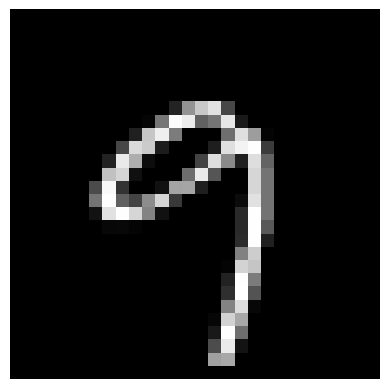

In [ ]:
import matplotlib.pyplot as plt

# Choisir une image
index = 677

# Récupérer les 784 pixels
image = X_dev[:, index]

# Transformer les 784 pixels en image 28x28
image = image.reshape(28, 28)

# Afficher l'image
plt.imshow(image, cmap='gray')
plt.axis('off')
plt.show()

In [ ]:
print("correct digit here is :" , Y_dev[677])

correct digit here is : 9


In [ ]:
# envoyer l image dans le resau
Z1 , A1 , Z2 , A2 = forward_prop(W1 , b1 , W2 , b2 ,X_dev[:, index : index+1])

# recuperer la prediction
prediction = get_predictions(A2)

print ( " le resau a estime que la reponse est la suivante : " , prediction)

 le resau a estime que la reponse est la suivante :  [9]
